# Assignment 2: Convolutional Autoencoders

**Authors:**
**Jessica Tambo Epoh (i6436881)**
**Vlad Stefan (i6342904)**


## Software description and how to use it

### What this notebook does

This notebook combines the code and the report. It covers:

1. **Exercise 1:** a convolutional autoencoder (CAE) that compresses CIFAR-10 images and reconstructs them.
2. **Exercise 2:** the size of the latent space, and experiments with other architectures.
3. **Exercise 3:** colourisation, where the network receives a grayscale image and predicts its colours.

**Library:** Keras (TensorFlow backend).

### Requirements
Python 3,TensorFlow, NumPy, Matplotlib, pandas.   
CIFAR-10 is downloaded automatically by Keras the first time the notebook runs.

### How to run
Run all cells from top to bottom. The notebook trains 13 networks in total, so a GPU is recommended.   
All models use the random seed 42, so results can be reproduced, apart from small differences between machines.

In [1]:
import keras
from keras import layers
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Exercise 1: Building the autoencoder

### Data

CIFAR-10 comes split into 50,000 training and 10,000 test images. We merged them back into one set of 60,000 images, shuffled them with a fixed seed, and split them into:

- Training set (80%): 48,000 images, used to learn the weights
- Validation set (10%): 6,000 images, used to monitor the error during training
- Test set (10%): 6,000 images, used only once at the end, to measure the final error

Shuffling makes sure that all three sets contain a similar mix of images, so the test error is a fair estimate. The class labels are not used, because the target of an autoencoder is the image itself.

Normalisation: pixel values were rescaled from $[0, 255]$ to $[0, 1]$ by dividing by 255. Small input values make training more stable, and this range matches the output of the sigmoid in the last layer of the network, which also produces values between 0 and 1.

In [ ]:
# loading CIFAR-10
(x_a, _), (x_b, _) = keras.datasets.cifar10.load_data()

full_cifar = np.concatenate((x_a, x_b)) # joining back the pre-split dataset into one 60k images array
rng = np.random.default_rng(42)
idx = rng.permutation(len(full_cifar))
shuffled_cifar = full_cifar[idx]
[x_train, x_val, x_test] = np.split(shuffled_cifar, [int(0.8*len(shuffled_cifar)), int(0.9*len(shuffled_cifar))])

# normalising
x_train = x_train.astype(np.float32) / 255
x_test = x_test.astype(np.float32) / 255
x_val = x_val.astype(np.float32) / 255

### Architecture

An autoencoder has two parts:

- The encoder compresses the image into a smaller representation, the latent space. To do this, it has to keep the most important information (shapes, colours, textures) and drop the rest.
- The decoder receives only this latent representation and tries to rebuild the original image from it.

Because the decoder never sees the original image, the encoder is forced to learn a compact description of it.

We built the 9-layer architecture from the assignment with Keras `Sequential`:

| # | Layer | Output shape | Role |
|---|---|---|---|
| | Input | 32 × 32 × 3 | RGB image |
| 1 | Conv2D, 3×3, 8 filters, ReLU | 32 × 32 × 8 | encoder: detect simple patterns (edges, colours) |
| 2 | MaxPooling 2×2 | 16 × 16 × 8 | encoder: halve width and height |
| 3 | Conv2D, 3×3, 12 filters, ReLU | 16 × 16 × 12 | encoder: combine patterns |
| 4 | MaxPooling 2×2 | 8 × 8 × 12 | encoder: halve width and height again |
| 5 | Conv2D, 3×3, 16 filters, ReLU | **8 × 8 × 16** | **latent space representation** |
| 6 | UpSampling 2×2 | 16 × 16 × 16 | decoder: double width and height |
| 7 | Conv2D, 3×3, 12 filters, ReLU | 16 × 16 × 12 | decoder: rebuild details |
| 8 | UpSampling 2×2 | 32 × 32 × 12 | decoder: back to full size |
| 9 | Conv2D, 3×3, 3 filters, sigmoid | 32 × 32 × 3 | reconstructed RGB image |

- Convolutional layers slide small 3×3 filters over the image. Each filter learns to detect one kind of local pattern, and each output channel holds the response of one filter.
- Max pooling keeps the largest value in every 2×2 block, which halves the width and height.
- Upsampling repeats every value in a 2×2 block, which doubles the width and height. The convolution after it learns to smooth and refine the enlarged image.
- Padding "same" and stride 1 in all convolutions keep the width and height unchanged, so only pooling and upsampling change the image size.
- ReLU is used in the hidden layers: it is simple and fast, and it does not saturate for positive values, so gradients flow well during training.
- Sigmoid in the last layer keeps every output pixel between 0 and 1, like the normalised input.

The network has 4,911 trainable parameters.

In [3]:
keras.utils.set_random_seed(42)   # same random start for every experiment
model = keras.Sequential([
    keras.Input(shape=(32,32,3)), # input image size and its 3 channels, RGB

    # Encoder: layers 1-5
    layers.Conv2D(8, kernel_size=3, padding='same', activation='relu'),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(12, kernel_size=3, padding='same', activation='relu'),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(16, kernel_size=3, padding='same', activation='relu'), # latent space representation

    # Decoder: layers 6-9
    layers.UpSampling2D(size=2),
    layers.Conv2D(12, kernel_size=3, padding='same', activation='relu'),
    layers.UpSampling2D(size=2),
    layers.Conv2D(3, kernel_size=3, padding='same', activation='sigmoid'), # inputs reconstruction
])

model.compile(optimizer="adam", loss="mse")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 8)      │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 12)     │           876 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 12)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 16)       │         1,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 12)     │         1,740 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 32, 32, 12)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 3)      │           327 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,911 (19.18 KB)

 Trainable params: 4,911 (19.18 KB)

 Non-trainable params: 0 (0.00 B)

### Training

- Input and target are the same image (`x_train, x_train`): the network learns to copy its input through the bottleneck.
- Loss: mean squared error (MSE), the average squared difference between the original and the reconstructed pixel values.
- Optimiser: Adam, a version of gradient descent that adapts the step size for every weight.
- Training: 10 epochs, batch size 64 (750 weight updates per epoch). The validation set is evaluated after every epoch.

In [4]:
history = model.fit(
    x_train, x_train,                    # same input and target images
    validation_data=(x_val, x_val),
    epochs=10,
    batch_size=64,
)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - loss: 0.0136 - val_loss: 0.0081
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 15s 20ms/step - loss: 0.0072 - val_loss: 0.0069
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 15s 20ms/step - loss: 0.0065 - val_loss: 0.0063
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - loss: 0.0061 - val_loss: 0.0060
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - loss: 0.0058 - val_loss: 0.0057
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - loss: 0.0056 - val_loss: 0.0055
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - loss: 0.0054 - val_loss: 0.0054
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - loss: 0.0053 - val_loss: 0.0052
Epoch 9/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - loss: 0.0052 - val_loss: 0.0051
Epoch 10/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - loss: 0.0051 - val_loss: 0.0050


### Learning curve

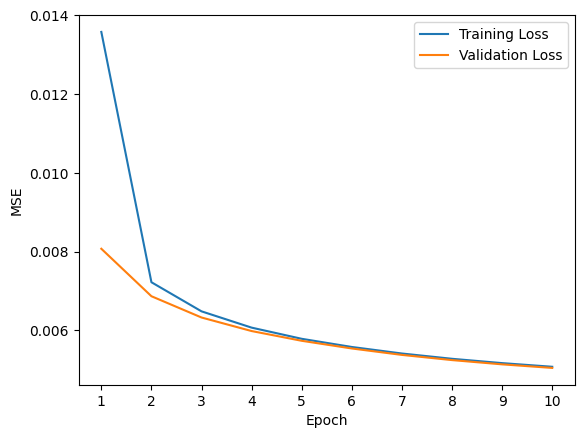

In [5]:
epochs = range(1, len(history.history["loss"]) + 1)
plt.plot(epochs, history.history["loss"], label="Training Loss")
plt.plot(epochs, history.history["val_loss"], label="Validation Loss")
plt.xticks(epochs)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.show()

Both curves go down quickly in the first epochs and then flatten.   
The training error drops from 0.0136 to 0.0051 and the validation error from 0.0081 to 0.0050.   
The validation error stays at the same level as the training error, so the network does not overfit: it reconstructs images it has never seen just as well as the training images. Both curves are still decreasing slightly at epoch 10, so longer training would lower the error a little further.

### Test error

In [6]:
test_mse = model.evaluate(x_test, x_test)
print("Test MSE:", test_mse)

188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0050
Test MSE: 0.004973175935447216


The test MSE (0.0050) is the same as the final validation MSE (0.0050), which confirms that the model generalises to new images.   
The square root of the MSE is about 0.07, so on average a reconstructed pixel value is off by about 7% of the full brightness range (about 18 out of 255).

### Example reconstructions

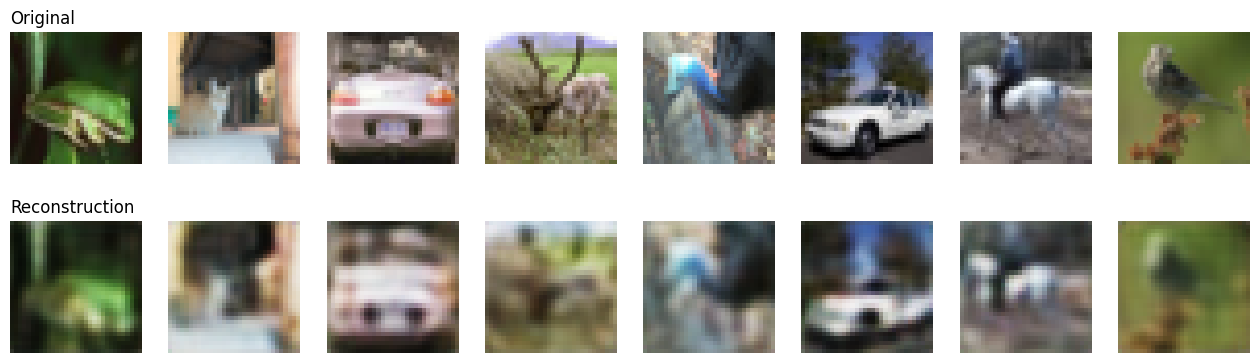

In [7]:
# original test images (top) and their reconstructions by the autoencoder (bottom)
n = 8
reconstructed = model.predict(x_test[:n], verbose=0)

plt.figure(figsize=(2 * n, 4.5))
for i in range(n):
    plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i])
    plt.axis("off")
    if i == 0: plt.title("Original", loc="left")

    plt.subplot(2, n, n + i + 1)
    plt.imshow(reconstructed[i])
    plt.axis("off")
    if i == 0: plt.title("Reconstruction", loc="left")
plt.show()

The reconstructions keep the main colours and the rough layout of each image: the green frog, the white car and the blue sky can still be seen. However, they are very blurry: edges and fine details are lost, and smaller objects, such as the deer, are hard to recognise. This is expected, because all information has to pass through the narrow middle of the network, where the image is reduced to an 8 × 8 grid, and max pooling throws away three out of every four values.

## Exercise 2: Latent space and architecture variations

### Exercise 2.1: Size of the latent space representation

The latent space representation is the output of layer 5 (the convolution with 16 channels). Its size follows from applying formula (1) layer by layer:

$$W_{\text{out}} = \left\lfloor \frac{W - K + 2P}{S} \right\rfloor + 1, \qquad \text{size} = W_{\text{out}} \times W_{\text{out}} \times C$$

where $W$ is the input width and height, $K$ the kernel size, $P$ the padding, $S$ the stride and $C$ the number of channels. The convolutional layers use $K = 3$, $P = 1$, $S = 1$, and the max pooling layers use $K = 2$, $P = 0$, $S = 2$. Pooling layers keep the number of channels of their input. The input image is $32 \times 32 \times 3$.

**Layer 1: convolution, 3×3, 8 channels**

$$W_1 = \left\lfloor \frac{32 - 3 + 2 \cdot 1}{1} \right\rfloor + 1 = 31 + 1 = 32 \quad\Rightarrow\quad 32 \times 32 \times 8$$

**Layer 2: max pooling, 2×2**

$$W_2 = \left\lfloor \frac{32 - 2 + 2 \cdot 0}{2} \right\rfloor + 1 = 15 + 1 = 16 \quad\Rightarrow\quad 16 \times 16 \times 8$$

**Layer 3: convolution, 3×3, 12 channels**

$$W_3 = \left\lfloor \frac{16 - 3 + 2 \cdot 1}{1} \right\rfloor + 1 = 15 + 1 = 16 \quad\Rightarrow\quad 16 \times 16 \times 12$$

**Layer 4: max pooling, 2×2**

$$W_4 = \left\lfloor \frac{16 - 2 + 2 \cdot 0}{2} \right\rfloor + 1 = 7 + 1 = 8 \quad\Rightarrow\quad 8 \times 8 \times 12$$

**Layer 5: convolution, 3×3, 16 channels (latent space)**

$$W_5 = \left\lfloor \frac{8 - 3 + 2 \cdot 1}{1} \right\rfloor + 1 = 7 + 1 = 8 \quad\Rightarrow\quad 8 \times 8 \times 16$$

**Result**

$$\text{latent size} = 8 \times 8 \times 16 = 1024$$

The encoder compresses each image from $32 \times 32 \times 3 = 3072$ values to $1024$ values.

### Exercise 2.2: Testing different architectures

To see how the architecture affects the reconstruction error, the baseline from Exercise 1 was changed one property at a time. Every model was trained in exactly the same way: the same data split, 10 epochs, batch size 64, the Adam optimiser, MSE loss and the same random seed (42). The baseline numbers come from the Exercise 1 run. The models are compared on the validation MSE after the last epoch, and the test MSE is reported next to it.

| Experiment | Change from the baseline |
|---|---|
| latent channels 2 to 64 | Number of channels in the latent layer |
| 5x5 filters | 5×5 kernels in every convolution instead of 3×3 |
| fewer layers | One max pooling and one upsampling instead of two (6 layers) |
| more layers | A third max pooling and upsampling + 2 extra conv layers (13 layers) |
| strided convs | The max pooling layers are replaced by convolutions with stride 2 |


Two sizes are recorded for every model:

- **Latent size:** the number of values in the output of the latent layer.
- **Narrowest layer:** the smallest layer output anywhere in the network. All information has to pass through this layer, so it is the real bottleneck. In the baseline architecture this is the second max pooling layer (8 × 8 × 12 = 768 values), not the latent layer (1024 values), because the latent layer is computed from those 768 values.

In [8]:
results = []   # one dictionary per experiment (re-running this cell clears all experiments)

In [9]:
def run_experiment(name, model, epochs=10):
    model.compile(optimizer="adam", loss="mse")
    history = model.fit(
        x_train, x_train,
        validation_data=(x_val, x_val),
        epochs=epochs,
        batch_size=64,
        verbose=2,
    )
    test_mse = model.evaluate(x_test, x_test, verbose=0)

    latent_size = int(np.prod(model.get_layer("latent").output.shape[1:]))
    narrowest = min(int(np.prod(layer.output.shape[1:])) for layer in model.layers)
    val_mse = history.history["val_loss"][-1]   # validation error after the last epoch
    results.append({
        "name": name,
        "latent_size": latent_size,
        "narrowest": narrowest,
        "val_mse": val_mse,
        "test_mse": test_mse,
        "history": history.history,
    })
    print(f"{name}: latent size {latent_size}, narrowest layer {narrowest}, validation MSE {val_mse:.5f}")

In [10]:
def build_cae(latent_channels=16, kernel_size=3):
    keras.utils.set_random_seed(42)   # same random start for every model built here
    return keras.Sequential([
        keras.Input(shape=(32, 32, 3)),

        # Encoder layers
        layers.Conv2D(8, kernel_size=kernel_size, padding='same', activation='relu'),
        layers.MaxPooling2D(pool_size=2),
        layers.Conv2D(12, kernel_size=kernel_size, padding='same', activation='relu'),
        layers.MaxPooling2D(pool_size=2),
        layers.Conv2D(latent_channels, kernel_size=kernel_size, padding='same', activation='relu', name='latent'), # latent space representation

        # Decoder layers
        layers.UpSampling2D(size=2),
        layers.Conv2D(12, kernel_size=kernel_size, padding='same', activation='relu'),
        layers.UpSampling2D(size=2),
        layers.Conv2D(3, kernel_size=kernel_size, padding='same', activation='sigmoid'), # inputs reconstruction
    ])

In [11]:
# Reuse the Exercise 1 run instead of training the same model again
results.append({
    "name": "baseline",
    "latent_size": 8 * 8 * 16,   # 1024, from Exercise 2.1
    "narrowest": 8 * 8 * 12,     # 768, the second max pooling layer
    "val_mse": history.history["val_loss"][-1],
    "test_mse": test_mse,
    "history": history.history,
})

In [12]:
for c in [2, 4, 8, 12, 32, 64]:   # 16 channels is the baseline
    run_experiment(f"latent channels {c}", build_cae(latent_channels=c))

Epoch 1/10
750/750 - 12s - 16ms/step - loss: 0.0178 - val_loss: 0.0109
Epoch 2/10
750/750 - 11s - 14ms/step - loss: 0.0100 - val_loss: 0.0096
Epoch 3/10
750/750 - 11s - 14ms/step - loss: 0.0091 - val_loss: 0.0088
Epoch 4/10
750/750 - 11s - 14ms/step - loss: 0.0084 - val_loss: 0.0083
Epoch 5/10
750/750 - 11s - 14ms/step - loss: 0.0080 - val_loss: 0.0080
Epoch 6/10
750/750 - 10s - 13ms/step - loss: 0.0078 - val_loss: 0.0077
Epoch 7/10
750/750 - 11s - 15ms/step - loss: 0.0075 - val_loss: 0.0076
Epoch 8/10
750/750 - 12s - 16ms/step - loss: 0.0074 - val_loss: 0.0075
Epoch 9/10
750/750 - 10s - 14ms/step - loss: 0.0073 - val_loss: 0.0074
Epoch 10/10
750/750 - 10s - 14ms/step - loss: 0.0072 - val_loss: 0.0073
latent channels 2: latent size 128, narrowest layer 128, validation MSE 0.00733
Epoch 1/10
750/750 - 14s - 18ms/step - loss: 0.0150 - val_loss: 0.0086
Epoch 2/10
750/750 - 10s - 14ms/step - loss: 0.0077 - val_loss: 0.0073
Epoch 3/10
750/750 - 11s - 14ms/step - loss: 0.0069 - val_loss: 0.0

In [13]:
run_experiment("5x5 filters", build_cae(kernel_size=5))

Epoch 1/10
750/750 - 20s - 27ms/step - loss: 0.0144 - val_loss: 0.0090
Epoch 2/10
750/750 - 18s - 24ms/step - loss: 0.0077 - val_loss: 0.0070
Epoch 3/10
750/750 - 19s - 26ms/step - loss: 0.0067 - val_loss: 0.0066
Epoch 4/10
750/750 - 20s - 27ms/step - loss: 0.0061 - val_loss: 0.0062
Epoch 5/10
750/750 - 19s - 26ms/step - loss: 0.0058 - val_loss: 0.0056
Epoch 6/10
750/750 - 19s - 25ms/step - loss: 0.0055 - val_loss: 0.0054
Epoch 7/10
750/750 - 19s - 25ms/step - loss: 0.0053 - val_loss: 0.0054
Epoch 8/10
750/750 - 20s - 27ms/step - loss: 0.0051 - val_loss: 0.0052
Epoch 9/10
750/750 - 18s - 25ms/step - loss: 0.0049 - val_loss: 0.0049
Epoch 10/10
750/750 - 18s - 24ms/step - loss: 0.0048 - val_loss: 0.0050
5x5 filters: latent size 1024, narrowest layer 768, validation MSE 0.00497


In [14]:
keras.utils.set_random_seed(42)   # same random start for every experiment
model = keras.Sequential([
    keras.Input(shape=(32,32,3)),

    # Encoder: one max pooling instead of two
    layers.Conv2D(8, kernel_size=3, padding='same', activation='relu'),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(12, kernel_size=3, padding='same', activation='relu'),
    layers.Conv2D(16, kernel_size=3, padding='same', activation='relu', name='latent'),

    # Decoder: one upsampling instead of two
    layers.UpSampling2D(size=2),
    layers.Conv2D(3, kernel_size=3, padding='same', activation='sigmoid'),
])

run_experiment("fewer layers", model)

Epoch 1/10
750/750 - 15s - 19ms/step - loss: 0.0082 - val_loss: 0.0036
Epoch 2/10
750/750 - 12s - 16ms/step - loss: 0.0031 - val_loss: 0.0028
Epoch 3/10
750/750 - 12s - 16ms/step - loss: 0.0026 - val_loss: 0.0025
Epoch 4/10
750/750 - 12s - 16ms/step - loss: 0.0023 - val_loss: 0.0022
Epoch 5/10
750/750 - 12s - 16ms/step - loss: 0.0022 - val_loss: 0.0021
Epoch 6/10
750/750 - 12s - 16ms/step - loss: 0.0021 - val_loss: 0.0020
Epoch 7/10
750/750 - 11s - 14ms/step - loss: 0.0020 - val_loss: 0.0019
Epoch 8/10
750/750 - 12s - 15ms/step - loss: 0.0019 - val_loss: 0.0019
Epoch 9/10
750/750 - 11s - 15ms/step - loss: 0.0018 - val_loss: 0.0019
Epoch 10/10
750/750 - 11s - 15ms/step - loss: 0.0018 - val_loss: 0.0019
fewer layers: latent size 4096, narrowest layer 2048, validation MSE 0.00190


In [15]:
keras.utils.set_random_seed(42)   # same random start for every experiment
model = keras.Sequential([
    keras.Input(shape=(32,32,3)),

    # Encoder: a third max pooling, down to 4x4
    layers.Conv2D(8, kernel_size=3, padding='same', activation='relu'),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(12, kernel_size=3, padding='same', activation='relu'),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(16, kernel_size=3, padding='same', activation='relu'),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(16, kernel_size=3, padding='same', activation='relu', name='latent'),

    # Decoder: a third upsampling, back up to 32x32
    layers.UpSampling2D(size=2),
    layers.Conv2D(16, kernel_size=3, padding='same', activation='relu'),
    layers.UpSampling2D(size=2),
    layers.Conv2D(12, kernel_size=3, padding='same', activation='relu'),
    layers.UpSampling2D(size=2),
    layers.Conv2D(3, kernel_size=3, padding='same', activation='sigmoid'),
])

run_experiment("more layers", model)

Epoch 1/10
750/750 - 17s - 23ms/step - loss: 0.0217 - val_loss: 0.0153
Epoch 2/10
750/750 - 14s - 19ms/step - loss: 0.0141 - val_loss: 0.0133
Epoch 3/10
750/750 - 13s - 17ms/step - loss: 0.0126 - val_loss: 0.0124
Epoch 4/10
750/750 - 13s - 17ms/step - loss: 0.0119 - val_loss: 0.0117
Epoch 5/10
750/750 - 14s - 18ms/step - loss: 0.0114 - val_loss: 0.0113
Epoch 6/10
750/750 - 14s - 18ms/step - loss: 0.0110 - val_loss: 0.0110
Epoch 7/10
750/750 - 13s - 18ms/step - loss: 0.0107 - val_loss: 0.0106
Epoch 8/10
750/750 - 14s - 18ms/step - loss: 0.0105 - val_loss: 0.0106
Epoch 9/10
750/750 - 13s - 18ms/step - loss: 0.0103 - val_loss: 0.0104
Epoch 10/10
750/750 - 15s - 20ms/step - loss: 0.0101 - val_loss: 0.0103
more layers: latent size 256, narrowest layer 256, validation MSE 0.01028


In [16]:
keras.utils.set_random_seed(42)   # same random start for every experiment
model = keras.Sequential([
    keras.Input(shape=(32,32,3)),

    # Encoder: stride 2 in the convolutions replaces the max pooling layers
    layers.Conv2D(8, kernel_size=3, strides=2, padding='same', activation='relu'),
    layers.Conv2D(12, kernel_size=3, strides=2, padding='same', activation='relu'),
    layers.Conv2D(16, kernel_size=3, padding='same', activation='relu', name='latent'),

    # Decoder: same as the baseline
    layers.UpSampling2D(size=2),
    layers.Conv2D(12, kernel_size=3, padding='same', activation='relu'),
    layers.UpSampling2D(size=2),
    layers.Conv2D(3, kernel_size=3, padding='same', activation='sigmoid'),
])

run_experiment("strided convs", model)

Epoch 1/10
750/750 - 12s - 15ms/step - loss: 0.0113 - val_loss: 0.0062
Epoch 2/10
750/750 - 10s - 13ms/step - loss: 0.0056 - val_loss: 0.0052
Epoch 3/10
750/750 - 11s - 15ms/step - loss: 0.0049 - val_loss: 0.0047
Epoch 4/10
750/750 - 10s - 14ms/step - loss: 0.0046 - val_loss: 0.0045
Epoch 5/10
750/750 - 11s - 14ms/step - loss: 0.0043 - val_loss: 0.0043
Epoch 6/10
750/750 - 10s - 14ms/step - loss: 0.0041 - val_loss: 0.0041
Epoch 7/10
750/750 - 10s - 13ms/step - loss: 0.0040 - val_loss: 0.0039
Epoch 8/10
750/750 - 9s - 13ms/step - loss: 0.0038 - val_loss: 0.0038
Epoch 9/10
750/750 - 10s - 13ms/step - loss: 0.0037 - val_loss: 0.0036
Epoch 10/10
750/750 - 10s - 14ms/step - loss: 0.0036 - val_loss: 0.0035
strided convs: latent size 1024, narrowest layer 768, validation MSE 0.00353


The lowest MSE architecture to be used further

In [17]:
keras.utils.set_random_seed(42)   # same random start for every experiment
model = keras.Sequential([
    keras.Input(shape=(32,32,3)),

    # Encoder: fewer layers, with a strided convolution instead of the max pooling
    layers.Conv2D(8, kernel_size=3, strides=2, padding='same', activation='relu'),
    layers.Conv2D(12, kernel_size=3, padding='same', activation='relu'),
    layers.Conv2D(16, kernel_size=3, padding='same', activation='relu', name='latent'),

    # Decoder: one upsampling
    layers.UpSampling2D(size=2),
    layers.Conv2D(3, kernel_size=3, padding='same', activation='sigmoid'),
])

run_experiment("fewer layers + strided", model)

Epoch 1/10
750/750 - 12s - 16ms/step - loss: 0.0074 - val_loss: 0.0029
Epoch 2/10
750/750 - 11s - 14ms/step - loss: 0.0025 - val_loss: 0.0022
Epoch 3/10
750/750 - 12s - 17ms/step - loss: 0.0020 - val_loss: 0.0019
Epoch 4/10
750/750 - 12s - 15ms/step - loss: 0.0017 - val_loss: 0.0017
Epoch 5/10
750/750 - 10s - 14ms/step - loss: 0.0015 - val_loss: 0.0015
Epoch 6/10
750/750 - 10s - 13ms/step - loss: 0.0014 - val_loss: 0.0013
Epoch 7/10
750/750 - 10s - 13ms/step - loss: 0.0013 - val_loss: 0.0013
Epoch 8/10
750/750 - 10s - 13ms/step - loss: 0.0012 - val_loss: 0.0012
Epoch 9/10
750/750 - 10s - 13ms/step - loss: 0.0011 - val_loss: 0.0011
Epoch 10/10
750/750 - 10s - 13ms/step - loss: 0.0011 - val_loss: 0.0011
fewer layers + strided: latent size 4096, narrowest layer 2048, validation MSE 0.00105


### Comparisons between all tested architectures

In [18]:
table = pd.DataFrame(results).drop(columns="history").sort_values("val_mse")
table

,name,latent_size,narrowest,val_mse,test_mse
11,fewer layers + strided,4096,2048,0.001055,0.001036
8,fewer layers,4096,2048,0.001899,0.001869
10,strided convs,1024,768,0.003529,0.003473
6,latent channels 64,4096,768,0.004330,0.004270
5,latent channels 32,2048,768,0.004692,0.004633
3,latent channels 8,512,512,0.004863,0.004802
4,latent channels 12,768,768,0.004870,0.004809
7,5x5 filters,1024,768,0.004975,0.004904
0,baseline,1024,768,0.005048,0.004973
2,latent channels 4,256,256,0.005657,0.005580


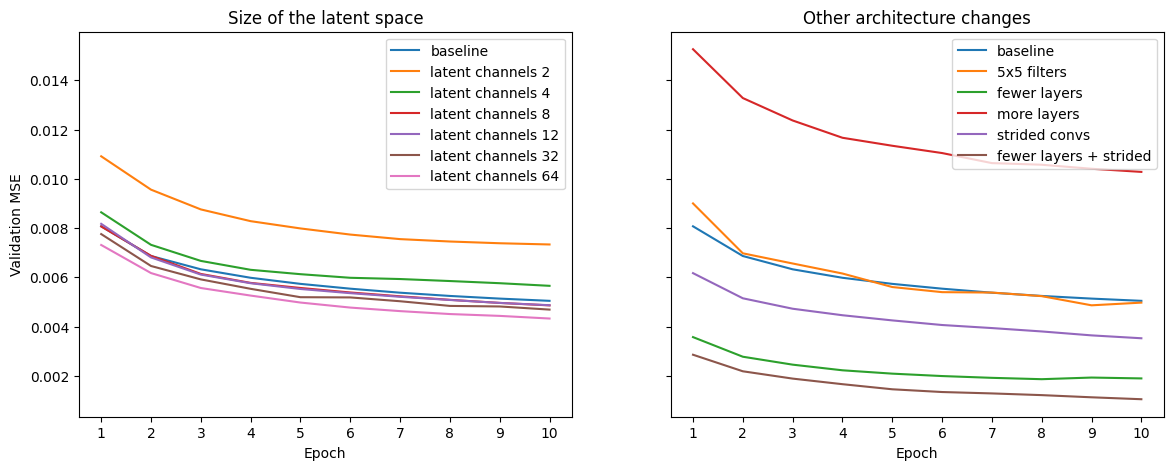

In [19]:
def in_sweep(r):   # the latent-channel runs, plus the baseline (16 channels)
    return r["name"].startswith("latent channels") or r["name"] == "baseline"

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for r in results:
    epoch_numbers = range(1, len(r["history"]["val_loss"]) + 1)
    if in_sweep(r):
        ax1.plot(epoch_numbers, r["history"]["val_loss"], label=r["name"])
    if not in_sweep(r) or r["name"] == "baseline":
        ax2.plot(epoch_numbers, r["history"]["val_loss"], label=r["name"])

ax1.set_title("Size of the latent space")
ax2.set_title("Other architecture changes")
ax1.set_ylabel("Validation MSE")
for ax in (ax1, ax2):
    ax.set_xlabel("Epoch")
    ax.set_xticks(range(1, 11))
    ax.legend()
plt.show()

Architectures are ranked by validation MSE. The test MSE follows the validation MSE closely for every model, and no validation curve starts rising, so there is no sign of overfitting within 10 epochs. Most curves are still going down at epoch 10, so all errors would drop further with longer training.

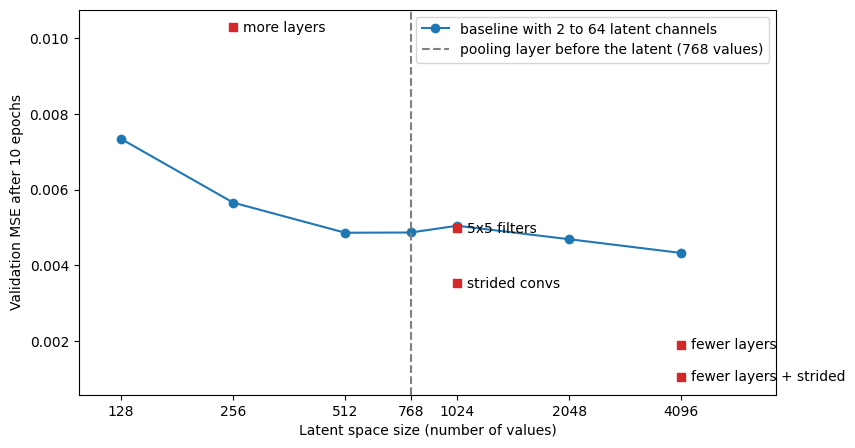

In [20]:
sweep = sorted([r for r in results if in_sweep(r)], key=lambda r: r["latent_size"])
others = [r for r in results if not in_sweep(r)]

plt.figure(figsize=(9, 5))
plt.plot([r["latent_size"] for r in sweep], [r["val_mse"] for r in sweep],
         marker="o", label="baseline with 2 to 64 latent channels")
for r in others:
    plt.scatter(r["latent_size"], r["val_mse"], marker="s", color="C3", zorder=3)
    plt.annotate(r["name"], (r["latent_size"], r["val_mse"]),
                 textcoords="offset points", xytext=(7, 0), va="center")
plt.axvline(768, linestyle="--", color="gray", label="pooling layer before the latent (768 values)")

plt.xscale("log", base=2)
sizes = sorted({r["latent_size"] for r in results})
plt.xticks(sizes, [str(s) for s in sizes])
plt.minorticks_off()
plt.xlim(sizes[0] / 1.3, sizes[-1] * 1.8)   # room for the labels on the right
plt.xlabel("Latent space size (number of values)")
plt.ylabel("Validation MSE after 10 epochs")
plt.legend()
plt.show()

**Size of the latent space.** The blue line is the baseline architecture ranging from 2 to 64 latent channels. The dashed line at 768 values splits it into two parts:

- **Left**: the latent layer is the narrowest layer. Here the error falls quickly as the latent space grows: from 0.0073 at 128 values to 0.0049 at 512 values, about a third lower.
- **Right**: the narrowest layer stays the 768-value max pooling layer before the latent layer, however many channels the latent layer gets. Making the latent space more than 5 times bigger (768 to 4096 values) lowers the error by only about 11%, and not steadily: the baseline (1024 values) is slightly worse than 512 and 768. The extra channels add weights, but no extra room for information, because everything still has to pass through the same 768 values. Differences of around 0.0002, like those between 8, 12 and 16 channels, are small enough to be run-to-run variation.

**Other architecture changes.** The red squares are the models that changed something other than the latent channels. Comparing each one with the blue point at the same latent size shows that the latent size alone does not decide the error:

- **Strided convolutions** (1024 values) reach 0.0035, ~30% lower than the baseline, even though the latent size and the narrowest layer (768) are the same. A likely reason: max pooling keeps only the largest of every four values and throws the rest away by a fixed rule, while a strided convolution learns how to combine neighbouring pixels as it downsamples, so it can keep more of the information the decoder needs.
- **5×5 filters** (1024 values) make almost no difference: 0.0050, only ~1.5% lower than the baseline, which is within run-to-run variation. Each filter sees a larger area of the image and has more weights, but this does not help much when the bottleneck stays the same.
- **Fewer layers** (4096 values) has less than half the error of the 64-channel model with the same latent size (0.0019 against 0.0043). With only one max pooling it keeps a 16 × 16 grid instead of 8 × 8, so its narrowest layer holds 2048 values instead of 768, and the decoder only has to upsample once.
- **More layers** (256 values) has almost twice the error of the 4-channel model with the same latent size (0.0103 against 0.0057). The third max pooling shrinks the image to a 4 × 4 grid, so each latent position has to describe an 8 × 8 pixel area. The deeper network also learns more slowly: its validation curve is still clearly falling at epoch 10.


## **Is there an obvious correlation between the size of the latent space and the error?**

Only within one architecture, and only while the latent layer is the bottleneck, in which case, a larger latent space clearly gives a lower error. Across architectures there is no simple correlation. Models with the same latent size differ by more than a factor of two, because the error depends on the size of the narrowest layer and on how the network downsamples (how much spatial resolution it keeps, and max pooling or strided convolution), not on the latent layer alone.

A lower error is not automatically a better autoencoder, though. The "best model" (fewer layers one) only compresses the 3072 input values to 2048 at its narrowest point (1.5 times), while the baseline compresses them to 768 (4 times). Compressing less makes reconstruction easier, so there is a trade-off between how compact the representation is and how accurately the image can be reconstructed.

**Limitations.** Each model was trained once, for 10 epochs. Deeper models may need more epochs to catch up, and differences of around 0.0002 may be noise.

**Best configuration for Exercise 3.** An architecture with fewer layers + strided convolution has achieved the lowest validation MSE (0.001055, test MSE 0.001036).

## Exercise 3: Colourisation

### Setup

The autoencoder is now trained on a different task: it receives a grayscale image and has to predict the colour image. Input and target are therefore no longer the same tensor:

- Input: the grayscale version of each image (32 × 32 × 1), computed with the standard luminance weights $Y = 0.299\,R + 0.587\,G + 0.114\,B$. Green has the largest weight because the human eye is most sensitive to it.
- Target: the original colour image (32 × 32 × 3).

The same train/validation/test split as in Exercises 1 and 2 is used, so all results are comparable.   Grayscaling is easy to compute, but its inverse is not, which is exactly the kind of mapping an autoencoder can learn without any labels.

In [21]:
# grayscale inputs, colour targets
gray_weights = np.array([0.299, 0.587, 0.114], dtype=np.float32)   # how much red, green, blue

def to_gray(x):
    # x has shape (number of images, 32, 32, 3)
    # result has shape (number of images, 32, 32, 1): one brightness value per pixel
    return (x @ gray_weights)[..., np.newaxis]

g_train = to_gray(x_train)
g_val   = to_gray(x_val)
g_test  = to_gray(x_test)

print(x_train.shape, "->", g_train.shape)

(48000, 32, 32, 3) -> (48000, 32, 32, 1)


### Network

As a starting point we used the best architecture from Exercise 2.2 ("fewer layers + strided"). The only change is the input: 1 channel instead of 3. The output still has 3 channels (R, G, B) with a sigmoid. The training settings are the same as before (Adam, MSE, 10 epochs, batch size 64).

In [22]:
keras.utils.set_random_seed(42)   
color_model = keras.Sequential([
    keras.Input(shape=(32, 32, 1)),   # grey image: 1 channel (was 3)

    # Encoder 
    layers.Conv2D(8, kernel_size=3, strides=2, padding='same', activation='relu'),
    layers.Conv2D(12, kernel_size=3, padding='same', activation='relu'),
    layers.Conv2D(16, kernel_size=3, padding='same', activation='relu', name='latent'),

    # Decoder
    layers.UpSampling2D(size=2),
    layers.Conv2D(3, kernel_size=3, padding='same', activation='sigmoid'),   # 3 channels: R, G, B
])

color_model.compile(optimizer="adam", loss="mse")
color_model.summary()

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_49 (Conv2D)              │ (None, 16, 16, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_50 (Conv2D)              │ (None, 16, 16, 12)     │           876 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Conv2D)                 │ (None, 16, 16, 16)     │         1,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_23 (UpSampling2D) │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_51 (Conv2D)              │ (None, 32, 32, 3)      │           435 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,135 (12.25 KB)

 Trainable params: 3,135 (12.25 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
color_history = color_model.fit(
    g_train, x_train,                    # input: grey images, target: colour images
    validation_data=(g_val, x_val),
    epochs=10,
    batch_size=64,
)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - loss: 0.0128 - val_loss: 0.0085
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 0.0079 - val_loss: 0.0077
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - loss: 0.0074 - val_loss: 0.0075
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - loss: 0.0072 - val_loss: 0.0073
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - loss: 0.0071 - val_loss: 0.0071
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 0.0069 - val_loss: 0.0070
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - loss: 0.0069 - val_loss: 0.0070
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - loss: 0.0068 - val_loss: 0.0069
Epoch 9/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 0.0067 - val_loss: 0.0069
Epoch 10/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 0.0067 - val_loss: 0.0069


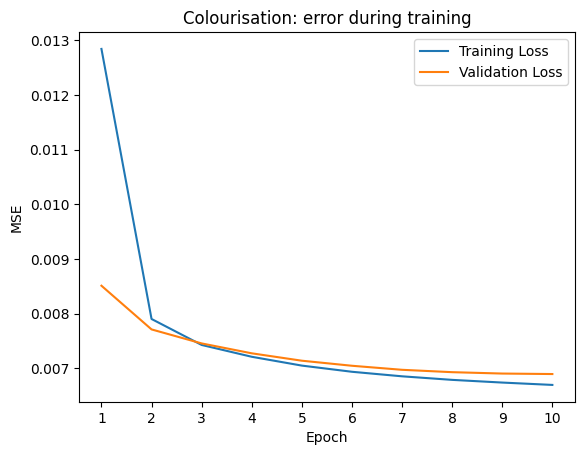

In [24]:
epochs = range(1, len(color_history.history["loss"]) + 1)
plt.plot(epochs, color_history.history["loss"], label="Training Loss")
plt.plot(epochs, color_history.history["val_loss"], label="Validation Loss")
plt.xticks(epochs)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Colourisation: error during training")
plt.legend()
plt.show()

The error drops quickly in the first two epochs and then flattens at about 0.0069. Training and validation errors stay close, so there is no overfitting, but more epochs would not help much: the network has reached its limit for this setup.

In [25]:
color_test_mse = color_model.evaluate(g_test, x_test, verbose=0)
print("Colourisation test MSE:", color_test_mse)

Colourisation test MSE: 0.006900263484567404


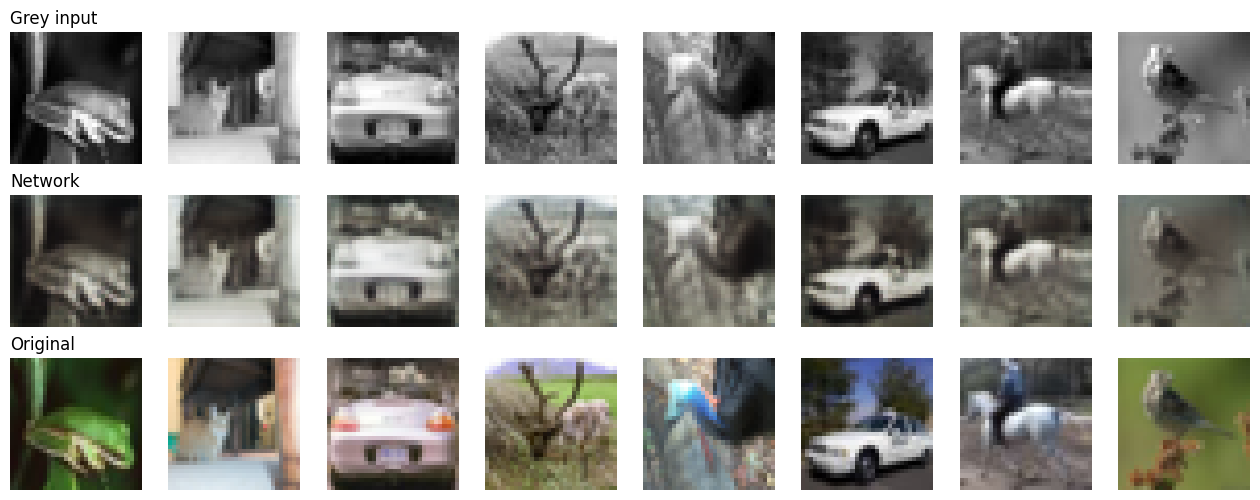

In [26]:
n = 8
predicted = color_model.predict(g_test[:n], verbose=0)

plt.figure(figsize=(2 * n, 6))
for i in range(n):
    # row 1: grey input
    plt.subplot(3, n, i + 1)
    plt.imshow(g_test[i].squeeze(), cmap="gray")
    plt.axis("off")
    if i == 0: plt.title("Grey input", loc="left")

    # row 2: network's colours
    plt.subplot(3, n, n + i + 1)
    plt.imshow(predicted[i])
    plt.axis("off")
    if i == 0: plt.title("Network", loc="left")

    # row 3: real colours
    plt.subplot(3, n, 2 * n + i + 1)
    plt.imshow(x_test[i])
    plt.axis("off")
    if i == 0: plt.title("Original", loc="left")
plt.show()

**Result:** the shapes and details are reproduced, but the network adds almost no colour. Most outputs are grey with only a faint brownish or greenish tint. For example, the frog should be bright green but stays dark grey.

**Why this happens:** a grayscale image often does not contain enough information to know the true colour. A car, a shirt or a bird can have any colour and still look the same in grayscale. With the MSE loss, the safest prediction in such cases is the average of all possible colours, and the average of many colours is a dull, desaturated grey-brown. Bold colour guesses are punished heavily when they are wrong, so the network learns to play it safe.

### Comparison with a trivial baseline

To judge the error of 0.0069, we compared it with the simplest possible "colouriser": copying the grayscale value into all three channels, which adds no colour at all.

In [27]:

lazy_prediction = np.repeat(g_test, 3, axis=-1)            # (6000, 32, 32, 1) -> (6000, 32, 32, 3)
lazy_mse = np.mean((lazy_prediction - x_test) ** 2)
print("Lazy grey-copy MSE:   ", lazy_mse)
print("Our network test MSE: ", color_test_mse)

Lazy grey-copy MSE:    0.0067498023
Our network test MSE:  0.006900263484567404


The network is slightly worse than adding no colour at all (0.00690 against 0.00675). It has to do two jobs at the same time: rebuild the whole image (shapes, edges and brightness) and predict the colours. It adds very little colour, and it also loses some detail, because the strided convolution reduces the image to 16 × 16 before the decoder enlarges it again. The grayscale copy keeps the brightness perfectly sharp.

### Improvement 1: predicting only the chrominance

Following the hint in the assignment, the network should not have to rebuild details that are already in the grayscale image. We converted every image from RGB to the YUV colour space:

- Y (luminance) is the brightness. It is computed with exactly the same weights as our grayscale images (the check below prints `True`).
- U and V (chrominance) contain only the colour information: U describes blue against yellow, V describes red against green.

The network now receives Y and predicts only U and V. The predicted U and V are then combined with the original Y and converted back to RGB. In this way, the details and contours come directly from the grayscale image, and the network can focus only on the colours.

In [29]:
import tensorflow as tf

yuv_train = tf.image.rgb_to_yuv(x_train).numpy()
yuv_val   = tf.image.rgb_to_yuv(x_val).numpy()
yuv_test  = tf.image.rgb_to_yuv(x_test).numpy()

y_train, uv_train = yuv_train[..., :1], yuv_train[..., 1:]   # input: Y, target: U and V
y_val,   uv_val   = yuv_val[..., :1],   yuv_val[..., 1:]
y_test,  uv_test  = yuv_test[..., :1],  yuv_test[..., 1:]

print("Brightness:", y_train.shape, " Colour:", uv_train.shape)
print("Same as our grey images", np.allclose(y_train, g_train, atol=1e-5))

Brightness: (48000, 32, 32, 1)  Colour: (48000, 32, 32, 2)
Same as our grey images True


The architecture is the same as before, but the last layer has 2 output channels (U and V) and a tanh activation instead of sigmoid, because U and V can be negative (roughly between −0.4 and 0.4 for U and between −0.6 and 0.6 for V), and tanh outputs values between −1 and 1.

In [30]:
keras.utils.set_random_seed(42)
uv_model = keras.Sequential([
    keras.Input(shape=(32, 32, 1)),   # brightness Y
    layers.Conv2D(8, kernel_size=3, strides=2, padding='same', activation='relu'),
    layers.Conv2D(12, kernel_size=3, padding='same', activation='relu'),
    layers.Conv2D(16, kernel_size=3, padding='same', activation='relu', name='latent'),
    layers.UpSampling2D(size=2),
    layers.Conv2D(2, kernel_size=3, padding='same', activation='tanh'),   # U and V (can be negative)
])
uv_model.compile(optimizer="adam", loss="mse")

uv_history = uv_model.fit(
    y_train, uv_train,                   # input: brightness, target: colour only
    validation_data=(y_val, uv_val),
    epochs=10,
    batch_size=64,
)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - loss: 0.0036 - val_loss: 0.0036
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - loss: 0.0034 - val_loss: 0.0036
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - loss: 0.0034 - val_loss: 0.0035
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - loss: 0.0034 - val_loss: 0.0035
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 0.0033 - val_loss: 0.0035
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - loss: 0.0033 - val_loss: 0.0035
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - loss: 0.0033 - val_loss: 0.0034
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - loss: 0.0033 - val_loss: 0.0034
Epoch 9/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 0.0033 - val_loss: 0.0034
Epoch 10/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 0.0033 - val_loss: 0.0034


To compare the models fairly, the predicted image is converted back to RGB and the MSE is computed in RGB, in the same way as for the other models.

In [31]:
pred_uv = uv_model.predict(y_test, verbose=0)
pred_yuv = np.concatenate([y_test, pred_uv], axis=-1)              # real Y + predicted U, V
pred_rgb = np.clip(tf.image.yuv_to_rgb(pred_yuv).numpy(), 0, 1)    # back to RGB

uv_rgb_mse = np.mean((pred_rgb - x_test) ** 2)
print("Lazy grey-copy MSE:      ", lazy_mse)
print("RGB network MSE:         ", color_test_mse)
print("Chrominance network MSE: ", uv_rgb_mse)

Lazy grey-copy MSE:       0.0067498023
RGB network MSE:          0.006900263484567404
Chrominance network MSE:  0.0057621724


Predicting only the chrominance lowers the error to 0.0058, which is about 15% better than the grayscale copy and the RGB network. This approach can never lose detail, because the brightness comes directly from the input. If the network predicted no colour at all (U = V = 0), the result would be exactly the grayscale copy, so any correct colour it adds is a direct improvement.

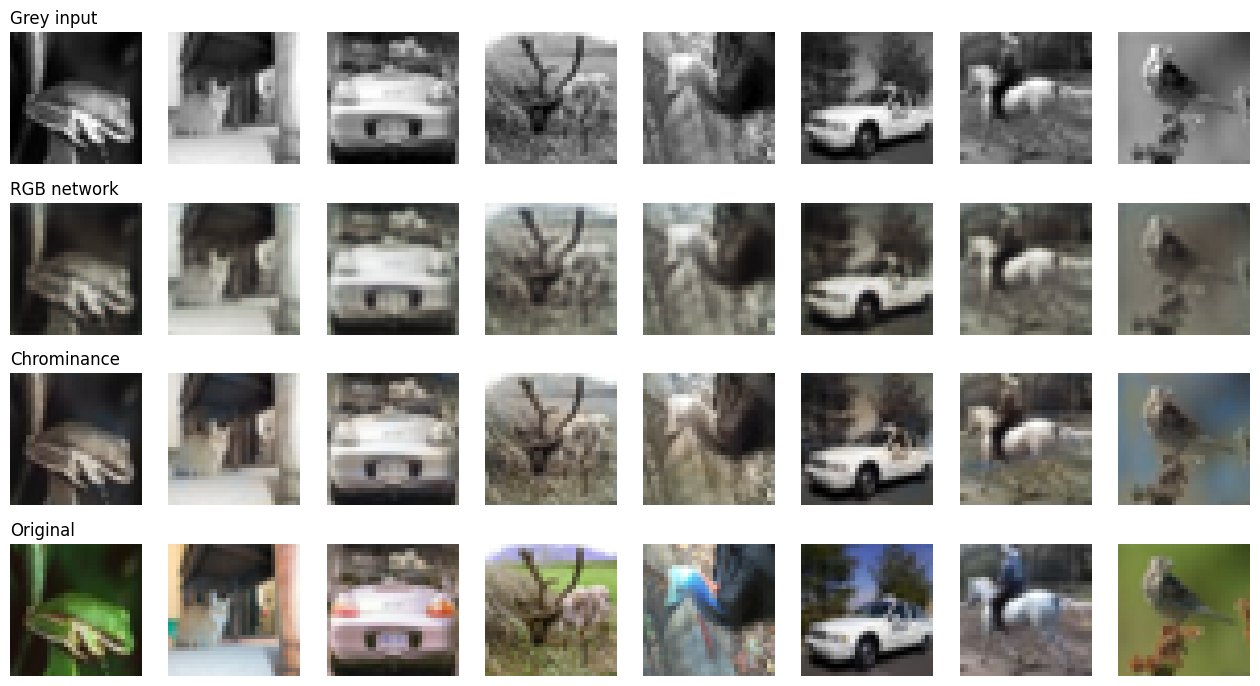

In [32]:
n = 8
pred_rgb_net = color_model.predict(g_test[:n], verbose=0)

rows = [
    ("Grey input",  [g_test[i].squeeze() for i in range(n)], "gray"),
    ("RGB network", [pred_rgb_net[i] for i in range(n)], None),
    ("Chrominance", [pred_rgb[i] for i in range(n)], None),
    ("Original",    [x_test[i] for i in range(n)], None),
]

plt.figure(figsize=(2 * n, 8.5))
for r, (title, images, cmap) in enumerate(rows):
    for i in range(n):
        plt.subplot(len(rows), n, r * n + i + 1)
        plt.imshow(images[i], cmap=cmap)
        plt.axis("off")
        if i == 0: plt.title(title, loc="left")
plt.show()

### Improvement 2: a bigger chrominance network

Choosing a colour often requires recognising what an object is, which needs context from a large part of the image. In the previous network, each output pixel depends on an area of only about 13 × 13 input pixels (its receptive field). We therefore made the network bigger:

- More filters (16, 32, 32 instead of 8, 12, 16), so it can learn more patterns.
- Two strided convolutions instead of one, so the image is reduced to 8 × 8 in the middle. Each output pixel now depends on an area of about 23 × 23 input pixels, most of the 32 × 32 image.
- Two upsampling steps in the decoder, to get back to 32 × 32.

The network has 19,978 parameters, almost 7 times more than the previous chrominance network (2,990).

In [33]:
keras.utils.set_random_seed(42)
big_uv_model = keras.Sequential([
    keras.Input(shape=(32, 32, 1)),   # brightness Y

    # Encoder: more filters, and shrink twice  
    layers.Conv2D(16, kernel_size=3, strides=2, padding='same', activation='relu'),   # 16x16
    layers.Conv2D(32, kernel_size=3, strides=2, padding='same', activation='relu'),   # 8x8
    layers.Conv2D(32, kernel_size=3, padding='same', activation='relu', name='latent'),

    # Decoder: grow back twice 
    layers.UpSampling2D(size=2),
    layers.Conv2D(16, kernel_size=3, padding='same', activation='relu'),
    layers.UpSampling2D(size=2),
    layers.Conv2D(8, kernel_size=3, padding='same', activation='relu'),
    layers.Conv2D(2, kernel_size=3, padding='same', activation='tanh'),   # U and V
])
big_uv_model.compile(optimizer="adam", loss="mse")
big_uv_model.summary()

big_uv_history = big_uv_model.fit(
    y_train, uv_train,
    validation_data=(y_val, uv_val),
    epochs=10,
    batch_size=64,
)

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_55 (Conv2D)              │ (None, 16, 16, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_56 (Conv2D)              │ (None, 8, 8, 32)       │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Conv2D)                 │ (None, 8, 8, 32)       │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_25 (UpSampling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_57 (Conv2D)              │ (None, 16, 16, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_26 (UpSampling2D) │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_58 (Conv2D)              │ (None, 32, 32, 8)      │         1,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_59 (Conv2D)              │ (None, 32, 32, 2)      │           146 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,978 (78.04 KB)

 Trainable params: 19,978 (78.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 19s 22ms/step - loss: 0.0035 - val_loss: 0.0034
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 16s 22ms/step - loss: 0.0034 - val_loss: 0.0034
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - loss: 0.0033 - val_loss: 0.0033
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 15s 20ms/step - loss: 0.0033 - val_loss: 0.0033
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - loss: 0.0032 - val_loss: 0.0033
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - loss: 0.0032 - val_loss: 0.0032
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - loss: 0.0032 - val_loss: 0.0032
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - loss: 0.0032 - val_loss: 0.0032
Epoch 9/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - loss: 0.0032 - val_loss: 0.0032
Epoch 10/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 16s 22ms/step - loss: 0.0031 - val_loss: 0.0032


In [34]:
pred_uv_big = big_uv_model.predict(y_test, verbose=0)
pred_rgb_big = np.clip(tf.image.yuv_to_rgb(np.concatenate([y_test, pred_uv_big], axis=-1)).numpy(), 0, 1)
big_uv_rgb_mse = np.mean((pred_rgb_big - x_test) ** 2)

print("Lazy grey-copy MSE:          ", lazy_mse)
print("RGB network MSE:             ", color_test_mse)
print("Chrominance network MSE:     ", uv_rgb_mse)
print("Bigger chrominance net MSE:  ", big_uv_rgb_mse)

Lazy grey-copy MSE:           0.0067498023
RGB network MSE:              0.006900263484567404
Chrominance network MSE:      0.0057621724
Bigger chrominance net MSE:   0.0053580254


### Results

| Method | Test MSE (RGB) | Compared with the grayscale copy |
|---|---|---|
| Grayscale copy (no colour) | 0.00675 | – |
| RGB network | 0.00690 | 2% worse |
| Chrominance network | 0.00576 | 15% better |
| Bigger chrominance network | 0.00536 | 21% better |

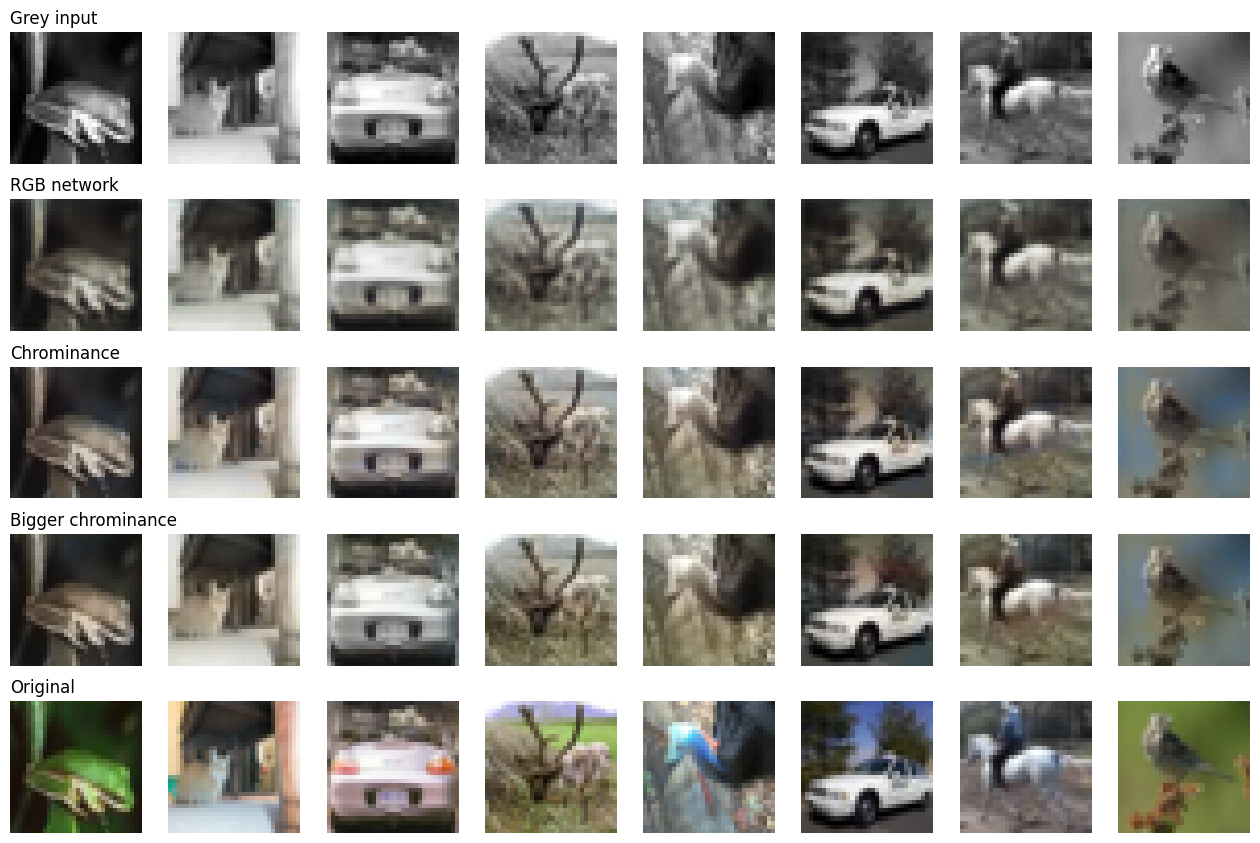

In [35]:
n = 8
rows = [
    ("Grey input",         [g_test[i].squeeze() for i in range(n)], "gray"),
    ("RGB network",        [pred_rgb_net[i] for i in range(n)], None),
    ("Chrominance",        [pred_rgb[i] for i in range(n)], None),
    ("Bigger chrominance", [pred_rgb_big[i] for i in range(n)], None),
    ("Original",           [x_test[i] for i in range(n)], None),
]

plt.figure(figsize=(2 * n, 10.5))
for r, (title, images, cmap) in enumerate(rows):
    for i in range(n):
        plt.subplot(len(rows), n, r * n + i + 1)
        plt.imshow(images[i], cmap=cmap)
        plt.axis("off")
        if i == 0: plt.title(title, loc="left")
plt.show()

**What improved:** the chrominance networks add visible colour, while the RGB network stays almost grey. The bigger network gives the most natural results, for example the trees and sky in the car image and the greener ground in the deer image.

**What is still wrong:**

- Colours are pale. Strong colours, such as the pink car or the blue jacket, never appear. This is the averaging effect of the MSE loss described above.
- Typical colours are guessed, even when they are wrong. Large smooth backgrounds tend to become blue, because in many photos they are sky. The bird's background becomes blue although it is green in reality. This reflects a bias in the dataset.
- Objects with a distinctive colour are not recognised. The frog stays grey instead of green, because the network is too small to recognise a frog from a 32 × 32 grayscale image.

### Limitations and possible improvements

The main limitations of our approach are:

- The MSE loss rewards safe, average colours, which leads to desaturated results.
- The networks are small and see only part of the image, so they cannot recognise objects well enough to know their colours.
- The images are very small (32 × 32), so there is little detail to recognise objects from.
- Training was short (10 epochs) and each model was trained only once.

Improvements we tried:

- Predicting only the chrominance (YUV): 15% lower error than the grayscale copy.
- A bigger network with a larger receptive field: a further improvement, to 21% lower error.

Further ideas we did not try:

- A different loss: treat colourisation as classification over a set of colour bins instead of regression with MSE, so the network can choose a bold colour instead of averaging. A perceptual or adversarial (GAN) loss would also favour realistic colours over the average.
- Skip connections (U-Net): connect encoder layers directly to decoder layers, so the decoder receives both the fine details and the large-scale context.
- A deeper network, or a pretrained encoder (for example, one trained on image classification), so the network can recognise objects.
- Longer training with more epochs, and data augmentation such as flipped images.

## Conclusion

We built a convolutional autoencoder with Keras that compresses 32 × 32 × 3 CIFAR-10 images into a latent representation of 8 × 8 × 16 = 1024 values and reconstructs them with a test MSE of 0.0050. The reconstructions keep the main colours and layout but are blurry.

The architecture experiments showed that the size of the latent space alone does not determine the error: the narrowest layer and the way the network downsamples matter more. Strided convolutions worked better than max pooling, and keeping a larger spatial resolution gave the lowest error, at the cost of less compression.

For colourisation, predicting the full RGB image produced almost grey images, slightly worse than a plain grayscale copy. Predicting only the chrominance and reusing the original brightness clearly improved the results, and a bigger network with a larger receptive field improved them further. The colours remain pale, mainly because the MSE loss favours average colours.

**What we learned** The most surprising result was that our first colourisation network was slightly worse than simply copying the grayscale image: it had to rebuild details it was already given, and it added almost no colour. This showed us how much the choice of what to predict matters, and predicting only the chrominance fixed both problems. We also did not expect the latent space size to be such a weak predictor of the error: the narrowest layer and the way of downsampling mattered more. Larger 5×5 filters, which we expected to help, made almost no difference. Finally, we learned that a lower error is not automatically a better autoencoder, because the best model in Exercise 2 achieved its low error partly by compressing much less.

## LLM Usage and Extra Reading

We used a Large Language Model (LLM), specifically Claude, as a supporting tool to clarify theoretical concepts, assist in debugging parts of the code, and to correct grammatical errors and refine the language of the report. The overall design and the final implementation were carried out by us,compared with the lecture formulas, and all LLM suggestions were critically evaluated and tested before being used.


## Team contribution

| Author | Code | Report | Video |
|---|---|---|---|
| Jessica Tambo Epoh | Exercise 3: colourisation (grayscale conversion, RGB network, chrominance network, bigger network), review and edited rest of the code | Exercise 3, conclusion, proofreading | 50% |
| Vlad Stefan | Exercises 1 and 2: data preparation, autoencoder, latent space calculation, architecture experiments, review and edited rest of the code | Exercises 1 and 2, proofreading | 50% |

<style>
pre { white-space: pre-wrap !important; }
</style>